In [1]:

#  Load Chennai dengue time-series data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

ROOT = Path.cwd().parent

cases = pd.read_csv(
    ROOT / "data/synthetic/disease_cases.csv",
    parse_dates=["year_month"]
)

# Select Chennai dengue under the baseline scenario
series_data = cases[
    (cases["district_id"] == "chn") &
    (cases["disease_id"] == "dengue") &
    (cases["scenario_id"] == "baseline")
].copy()

series_data = series_data.sort_values("year_month")

# Monthly time series
ts = series_data.set_index("year_month")["cases_per_100k"]
ts = ts.asfreq("MS")

# Chronological train/test split
train = ts.loc["2015-01":"2021-12"]
test = ts.loc["2022-01":"2024-12"]

print("=== CHENNAI DENGUE TIME SERIES ===")
print("Total months:", len(ts))
print("Training months:", len(train))
print("Testing months:", len(test))
print("Missing values:", ts.isna().sum())

print("\nTraining period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

display(series_data.head())


=== CHENNAI DENGUE TIME SERIES ===
Total months: 120
Training months: 84
Testing months: 36
Missing values: 0

Training period: 2015-01-01 00:00:00 to 2021-12-01 00:00:00
Testing period: 2022-01-01 00:00:00 to 2024-12-01 00:00:00


,year_month,district_id,disease_id,scenario_id,cases,cases_per_100k,data_type
0,2015-01-01,chn,dengue,baseline,275,3.929,synthetic_observed
1,2015-02-01,chn,dengue,baseline,179,2.557,synthetic_observed
2,2015-03-01,chn,dengue,baseline,175,2.500,synthetic_observed
3,2015-04-01,chn,dengue,baseline,53,0.757,synthetic_observed
4,2015-05-01,chn,dengue,baseline,50,0.714,synthetic_observed


In [2]:

# Train and evaluate ARIMA(2, 0, 2)

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

# Fit ARIMA using training data only (2015–2021)
arima_model = ARIMA(
    train,
    order=(2, 0, 2),
    enforce_stationarity=False,
    enforce_invertibility=False
)

arima_fit = arima_model.fit()

# Forecast the 36-month test period (2022–2024)
arima_forecast = arima_fit.forecast(steps=len(test))

# Calculate evaluation metrics
arima_mae = mean_absolute_error(test, arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(test, arima_forecast))

print("=== ARIMA(2,0,2) RESULTS ===")
print("Training months:", len(train))
print("Forecast months:", len(arima_forecast))
print("MAE:", round(arima_mae, 3))
print("RMSE:", round(arima_rmse, 3))

print("\nModel convergence:")
print(arima_fit.mle_retvals.get("converged", "Unknown"))

print("\nFirst 5 forecasts:")
display(
    pd.DataFrame({
        "Actual": test,
        "ARIMA_Predicted": arima_forecast
    }).head()
)


=== ARIMA(2,0,2) RESULTS ===
Training months: 84
Forecast months: 36
MAE: 1.232
RMSE: 2.489

Model convergence:
True

First 5 forecasts:


,Actual,ARIMA_Predicted
2022-01-01,3.071,3.703028
2022-02-01,2.429,3.185584
2022-03-01,1.914,2.577026
2022-04-01,1.429,2.036248
2022-05-01,1.314,1.691474


In [3]:

#  Train and evaluate SARIMA

from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(
    train,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 12),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False, maxiter=300)

# Forecast 2022–2024
sarima_forecast = sarima_fit.forecast(steps=len(test))

sarima_mae = mean_absolute_error(test, sarima_forecast)
sarima_rmse = np.sqrt(mean_squared_error(test, sarima_forecast))

print("=== SARIMA RESULTS ===")
print("Training months:", len(train))
print("Forecast months:", len(sarima_forecast))
print("MAE:", round(sarima_mae, 3))
print("RMSE:", round(sarima_rmse, 3))
print("Converged:", sarima_fit.mle_retvals.get("converged"))

print("\nFirst 5 forecasts:")
display(
    pd.DataFrame({
        "Actual": test,
        "SARIMA_Predicted": sarima_forecast
    }).head()
)


=== SARIMA RESULTS ===
Training months: 84
Forecast months: 36
MAE: 1.08
RMSE: 2.445
Converged: True

First 5 forecasts:


,Actual,SARIMA_Predicted
2022-01-01,3.071,3.153459
2022-02-01,2.429,2.784389
2022-03-01,1.914,2.307009
2022-04-01,1.429,1.815990
2022-05-01,1.314,1.648177


In [4]:

#  Prepare climate variables for SARIMAX

climate = pd.read_csv(
    ROOT / "data/synthetic/climate_history.csv",
    parse_dates=["year_month"]
)

# Chennai baseline climate only
chennai_climate = climate[
    (climate["district_id"] == "chn") &
    (climate["scenario_id"] == "baseline")
].copy()

chennai_climate = chennai_climate.sort_values("year_month")
chennai_climate = chennai_climate.set_index("year_month").asfreq("MS")

climate_features = [
    "rainfall_mm",
    "mean_temperature_c",
    "relative_humidity_pct"
]

exog_train = chennai_climate.loc[
    train.index, climate_features
]

exog_test = chennai_climate.loc[
    test.index, climate_features
]

print("=== SARIMAX CLIMATE DATA VERIFICATION ===")
print("Training climate shape:", exog_train.shape)
print("Testing climate shape:", exog_test.shape)

print("\nMissing training values:")
print(exog_train.isna().sum())

print("\nMissing testing values:")
print(exog_test.isna().sum())

print("\nTraining dates aligned:",
      exog_train.index.equals(train.index))

print("Testing dates aligned:",
      exog_test.index.equals(test.index))

display(exog_train.head())


=== SARIMAX CLIMATE DATA VERIFICATION ===
Training climate shape: (84, 3)
Testing climate shape: (36, 3)

Missing training values:
rainfall_mm              0
mean_temperature_c       0
relative_humidity_pct    0
dtype: int64

Missing testing values:
rainfall_mm              0
mean_temperature_c       0
relative_humidity_pct    0
dtype: int64

Training dates aligned: True
Testing dates aligned: True


,rainfall_mm,mean_temperature_c,relative_humidity_pct
year_month,,,
2015-01-01,14.8,28.0,67.0
2015-02-01,8.6,28.3,63.7
2015-03-01,9.0,31.3,70.4
2015-04-01,13.3,32.5,62.5
2015-05-01,23.7,31.9,69.5


In [5]:

# Train and evaluate climate-aware SARIMAX

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Scale climate inputs using TRAINING data only
exog_mean = exog_train.mean()
exog_std = exog_train.std().replace(0, 1)

exog_train_scaled = (exog_train - exog_mean) / exog_std
exog_test_scaled = (exog_test - exog_mean) / exog_std

# Fit SARIMAX with annual seasonality and climate inputs
sarimax_model = SARIMAX(
    train,
    exog=exog_train_scaled,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 12),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fit = sarimax_model.fit(
    disp=False,
    maxiter=300
)

# Forecast 36 months using synthetic climate scenario inputs
sarimax_forecast = sarimax_fit.forecast(
    steps=len(test),
    exog=exog_test_scaled
)

sarimax_mae = mean_absolute_error(test, sarimax_forecast)
sarimax_rmse = np.sqrt(
    mean_squared_error(test, sarimax_forecast)
)

print("=== SARIMAX RESULTS ===")
print("Training months:", len(train))
print("Forecast months:", len(sarimax_forecast))
print("MAE:", round(sarimax_mae, 3))
print("RMSE:", round(sarimax_rmse, 3))
print("Converged:", sarimax_fit.mle_retvals.get("converged"))

print("\nFirst 5 forecasts:")
display(
    pd.DataFrame({
        "Actual": test,
        "SARIMAX_Predicted": sarimax_forecast
    }).head()
)


=== SARIMAX RESULTS ===
Training months: 84
Forecast months: 36
MAE: 0.932
RMSE: 2.284
Converged: True

First 5 forecasts:


,Actual,SARIMAX_Predicted
2022-01-01,3.071,3.200940
2022-02-01,2.429,2.841491
2022-03-01,1.914,1.963282
2022-04-01,1.429,1.460769
2022-05-01,1.314,1.484346


In [6]:

# Prepare lagged climate variables for SARIMAX

# Use the complete baseline climate history so lags
# at the start of 2022 can use preceding months.
lagged_climate = chennai_climate[
    climate_features
].copy()

# Create one-month lagged variables
for col in climate_features:
    lagged_climate[f"{col}_lag1"] = (
        lagged_climate[col].shift(1)
    )

# Use previous-month rainfall and humidity,
# but retain current-month temperature.
lagged_features = [
    "rainfall_mm_lag1",
    "mean_temperature_c",
    "relative_humidity_pct_lag1"
]

lagged_train = lagged_climate.loc[
    train.index, lagged_features
].copy()

lagged_test = lagged_climate.loc[
    test.index, lagged_features
].copy()

print("=== LAGGED CLIMATE VERIFICATION ===")
print("Training shape:", lagged_train.shape)
print("Testing shape:", lagged_test.shape)

print("\nMissing training values:")
print(lagged_train.isna().sum())

print("\nMissing testing values:")
print(lagged_test.isna().sum())

display(lagged_train.head())


=== LAGGED CLIMATE VERIFICATION ===
Training shape: (84, 3)
Testing shape: (36, 3)

Missing training values:
rainfall_mm_lag1              1
mean_temperature_c            0
relative_humidity_pct_lag1    1
dtype: int64

Missing testing values:
rainfall_mm_lag1              0
mean_temperature_c            0
relative_humidity_pct_lag1    0
dtype: int64


,rainfall_mm_lag1,mean_temperature_c,relative_humidity_pct_lag1
year_month,,,
2015-01-01,NaN,28.0,NaN
2015-02-01,14.8,28.3,67.0
2015-03-01,8.6,31.3,63.7
2015-04-01,9.0,32.5,70.4
2015-05-01,13.3,31.9,62.5


In [7]:

#  Train and evaluate lagged SARIMAX

# Remove the first training month with missing lag values
lagged_train_clean = lagged_train.dropna()

# Align disease cases with available training climate data
train_lagged = train.loc[lagged_train_clean.index]

# Verify that test climate data has no missing values
assert not lagged_test.isna().any().any(), (
    "Missing values found in test climate features"
)

# Scale features using training data only
lagged_mean = lagged_train_clean.mean()
lagged_std = lagged_train_clean.std().replace(0, 1)

lagged_train_scaled = (
    lagged_train_clean - lagged_mean
) / lagged_std

lagged_test_scaled = (
    lagged_test - lagged_mean
) / lagged_std

# Train SARIMAX with lagged climate inputs
lagged_sarimax_model = SARIMAX(
    train_lagged,
    exog=lagged_train_scaled,
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 12),
    trend="c",
    enforce_stationarity=False,
    enforce_invertibility=False
)

lagged_sarimax_fit = lagged_sarimax_model.fit(
    disp=False,
    maxiter=300
)

# Forecast the same 36-month test period
lagged_sarimax_forecast = lagged_sarimax_fit.forecast(
    steps=len(test),
    exog=lagged_test_scaled
)

lagged_mae = mean_absolute_error(
    test, lagged_sarimax_forecast
)

lagged_rmse = np.sqrt(
    mean_squared_error(test, lagged_sarimax_forecast)
)

print("=== LAGGED SARIMAX RESULTS ===")
print("Training months:", len(train_lagged))
print("Forecast months:", len(lagged_sarimax_forecast))
print("MAE:", round(lagged_mae, 3))
print("RMSE:", round(lagged_rmse, 3))
print(
    "Converged:",
    lagged_sarimax_fit.mle_retvals.get("converged")
)

print("\n=== MODEL COMPARISON ===")

display(
    pd.DataFrame({
        "Model": [
            "ARIMA",
            "SARIMA",
            "SARIMAX",
            "Lagged SARIMAX"
        ],
        "MAE": [
            arima_mae,
            sarima_mae,
            sarimax_mae,
            lagged_mae
        ],
        "RMSE": [
            arima_rmse,
            sarima_rmse,
            sarimax_rmse,
            lagged_rmse
        ]
    }).round(3)
)


=== LAGGED SARIMAX RESULTS ===
Training months: 83
Forecast months: 36
MAE: 0.948
RMSE: 2.29
Converged: True

=== MODEL COMPARISON ===


,Model,MAE,RMSE
0,ARIMA,1.232,2.489
1,SARIMA,1.080,2.445
2,SARIMAX,0.932,2.284
3,Lagged SARIMAX,0.948,2.290


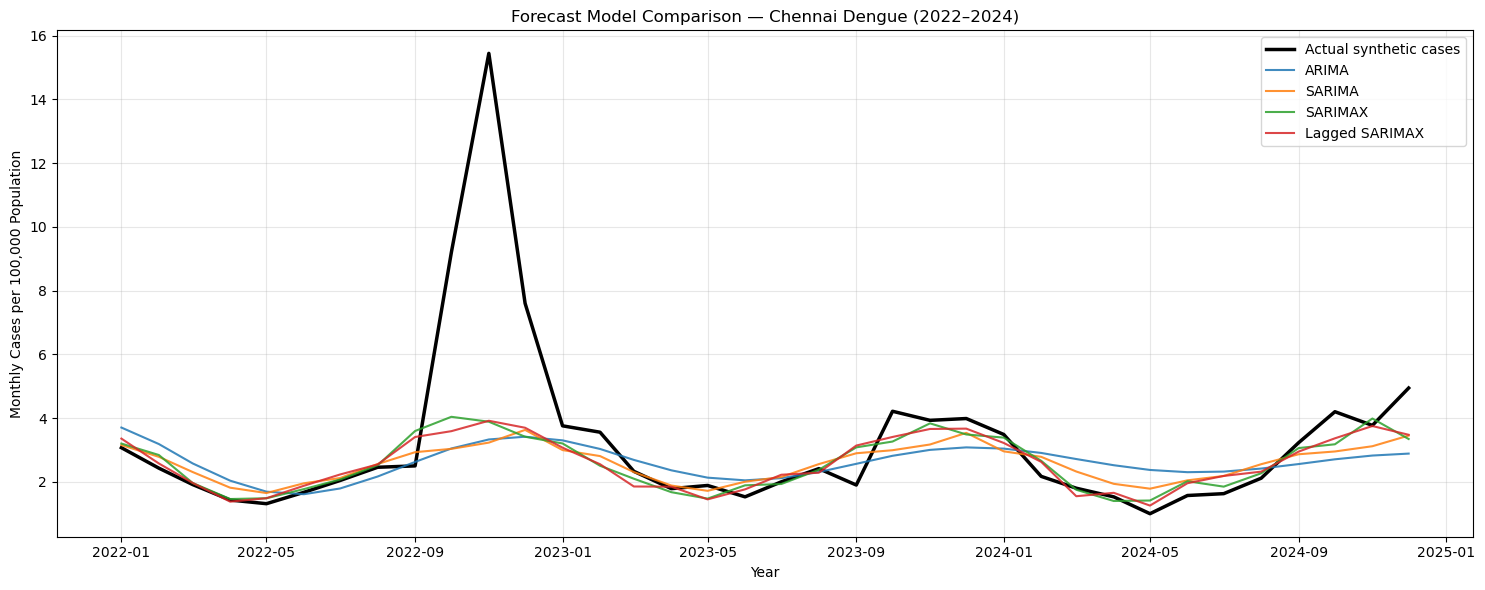

=== MODEL COMPARISON DATA ===


,Actual,ARIMA,SARIMA,SARIMAX,Lagged SARIMAX
year_month,,,,,
2022-01-01,3.071,3.703028,3.153459,3.200940,3.356176
2022-02-01,2.429,3.185584,2.784389,2.841491,2.575967
2022-03-01,1.914,2.577026,2.307009,1.963282,1.965454
2022-04-01,1.429,2.036248,1.815990,1.460769,1.377995
2022-05-01,1.314,1.691474,1.648177,1.484346,1.485909



Missing predictions:
Actual            0
ARIMA             0
SARIMA            0
SARIMAX           0
Lagged SARIMAX    0
dtype: int64


In [8]:

# Compare forecasting models visually

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

comparison = pd.DataFrame({
    "Actual": np.asarray(test),
    "ARIMA": np.asarray(arima_forecast),
    "SARIMA": np.asarray(sarima_forecast),
    "SARIMAX": np.asarray(sarimax_forecast),
    "Lagged SARIMAX": np.asarray(lagged_sarimax_forecast)
}, index=test.index)

plt.figure(figsize=(15, 6))

plt.plot(
    comparison.index,
    comparison["Actual"],
    label="Actual synthetic cases",
    color="black",
    linewidth=2.5
)

for model_name in [
    "ARIMA",
    "SARIMA",
    "SARIMAX",
    "Lagged SARIMAX"
]:
    plt.plot(
        comparison.index,
        comparison[model_name],
        label=model_name,
        linewidth=1.5,
        alpha=0.85
    )

plt.title(
    "Forecast Model Comparison — Chennai Dengue (2022–2024)"
)
plt.xlabel("Year")
plt.ylabel("Monthly Cases per 100,000 Population")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("=== MODEL COMPARISON DATA ===")
display(comparison.head())

print("\nMissing predictions:")
print(comparison.isna().sum())
